# RevPulse churn evaluation

This notebook reports the saved, once-evaluated chronological holdout. It does not tune on the test set.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from revpulse.core import current_run
root=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
run=current_run(root)
print('Run:',run.name)


Run: 20261107T082251_ebe78748


In [2]:
evaluation=json.loads((run/'analytics/model_evaluation.json').read_text())
pd.DataFrame(evaluation['splits']).T

,first,last,rows,churns
train,2023-01-31,2024-12-31,13526,293
validation,2025-01-31,2025-06-30,4507,109
test,2025-07-31,2025-11-30,3440,84


In [3]:
pd.DataFrame(evaluation['validation']).T[['pr_auc','precision','recall','f1','brier']]

,pr_auc,precision,recall,f1,brier
logistic_regression,0.09574,0.183333,0.201835,0.19214,0.022737
random_forest,0.106784,0.303571,0.155963,0.206061,0.022655


In [4]:
print('Selected:',evaluation['selected_model'],'threshold:',evaluation['threshold'])
pd.DataFrame({'selected':evaluation['test'],**evaluation['baselines']}).T[['pr_auc','precision','recall','f1','brier']]

Selected: random_forest threshold: 0.1485858585858586


,pr_auc,precision,recall,f1,brier
selected,0.138633,0.179104,0.142857,0.15894,0.022587
prevalence,0.024419,0.0,0.0,0.0,0.02383
operational_rule,0.057786,0.086705,0.535714,0.149254,0.129302


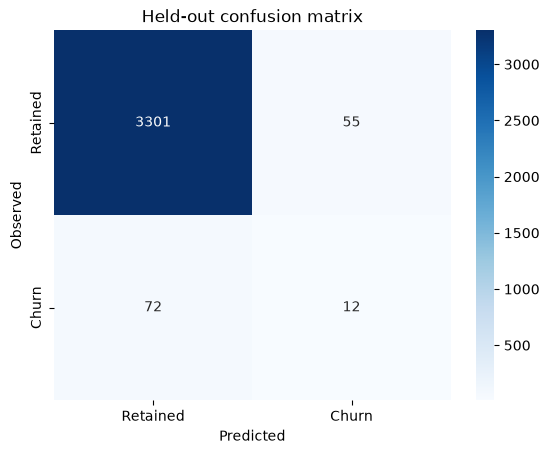

In [5]:
sns.heatmap(evaluation['test']['confusion_matrix'],annot=True,fmt='d',cmap='Blues',xticklabels=['Retained','Churn'],yticklabels=['Retained','Churn']); plt.xlabel('Predicted');plt.ylabel('Observed');plt.title('Held-out confusion matrix');plt.show()

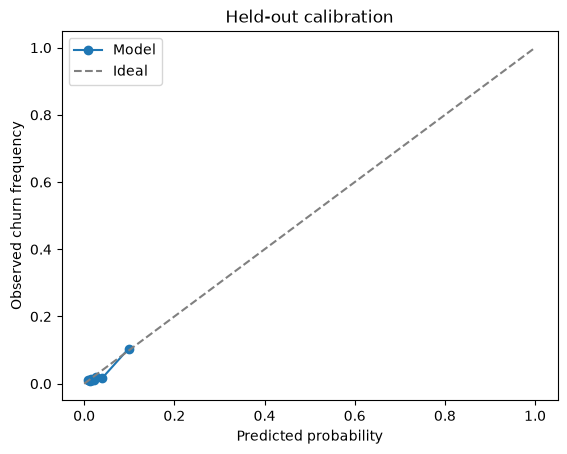

In [6]:
cal=evaluation['calibration'];plt.plot(cal['mean_probability'],cal['observed_frequency'],'o-',label='Model');plt.plot([0,1],[0,1],'--',color='gray',label='Ideal');plt.xlabel('Predicted probability');plt.ylabel('Observed churn frequency');plt.title('Held-out calibration');plt.legend();plt.show()

In [7]:
pd.DataFrame(evaluation['campaigns'])[['score_date','k','precision_at_k','recall_at_k','prevalence']]

,score_date,k,precision_at_k,recall_at_k,prevalence
0,2025-07-31,20,0.1,0.142857,0.019580
1,2025-08-31,20,0.2,0.181818,0.031117
2,2025-09-30,20,0.2,0.190476,0.030479
3,2025-10-31,20,0.2,0.266667,0.022388
4,2025-11-30,20,0.2,0.333333,0.018209


In [8]:
scores=pd.read_csv(run/'analytics/churn_predictions.csv');scores[['company_name','churn_probability','risk_category','mrr_inr','overdue_inr','usage_change','score_date']].head(20)

,company_name,churn_probability,risk_category,mrr_inr,overdue_inr,usage_change,score_date
0,RevPulse Demo Company 0597,0.287539,High,1000.0,11800.0,-0.060,2025-12-31
1,RevPulse Demo Company 0546,0.235040,High,20000.0,283200.0,-0.070,2025-12-31
2,RevPulse Demo Company 0016,0.218715,High,5000.0,2124.0,-0.080,2025-12-31
3,RevPulse Demo Company 0752,0.206938,High,900.0,95462.0,-0.160,2025-12-31
4,RevPulse Demo Company 0818,0.204516,High,1000.0,5900.0,0.020,2025-12-31
5,RevPulse Demo Company 0967,0.202463,High,1000.0,23600.0,-0.075,2025-12-31
6,RevPulse Demo Company 0279,0.195344,High,5000.0,0.0,-0.100,2025-12-31
7,RevPulse Demo Company 0354,0.195252,High,900.0,0.0,-0.060,2025-12-31
8,RevPulse Demo Company 0772,0.192404,High,1000.0,4602.0,0.000,2025-12-31
9,RevPulse Demo Company 0848,0.189312,High,5000.0,12095.0,-0.140,2025-12-31


## Limitations
Synthetic data demonstrates the pipeline, not validated commercial prediction. Existing accounts recur across chronological splits; unseen-account generalization is not evaluated. High-risk MRR is exposure, not expected loss. Current scores use the selected training-only model to preserve the documented evaluation; there is no silent retraining on held-out labels.